In [2]:
# ===============================================
# Roll no : 60       PRN: 0124UITM1060
# Name : Kshitij Shinde
# Dept. : Information Technology (Third Year)
# ===============================================
# Assignment 6:
# Credit Score Classification using Decision Tree
# ===============================================
# ---------------------------------------------------
# Import necessary libraries
# ---------------------------------------------------

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,precision_score,recall_score)
# ---------------------------------------------------
# 1. Load the dataset
# ---------------------------------------------------
df = pd.read_csv('Credit Score Classification Dataset.csv')
print(df.head())

   Age  Gender  Income            Education Marital Status  \
0   25  Female   50000    Bachelor's Degree         Single   
1   30    Male  100000      Master's Degree        Married   
2   35  Female   75000            Doctorate        Married   
3   40    Male  125000  High School Diploma         Single   
4   45  Female  100000    Bachelor's Degree        Married   

   Number of Children Home Ownership Credit Score  
0                   0         Rented         High  
1                   2          Owned         High  
2                   1          Owned         High  
3                   0          Owned         High  
4                   3          Owned         High  



Accuracy: 0.9393939393939394

Classification Report:
              precision    recall  f1-score   support

     Average       0.71      1.00      0.83         5
        High       1.00      0.91      0.95        23
         Low       1.00      1.00      1.00         5

    accuracy                           0.94        33
   macro avg       0.90      0.97      0.93        33
weighted avg       0.96      0.94      0.94        33


Confusion Matrix:
[[ 5  0  0]
 [ 2 21  0]
 [ 0  0  5]]

Precision Score: 0.9567099567099567
Recall Score: 0.9393939393939394


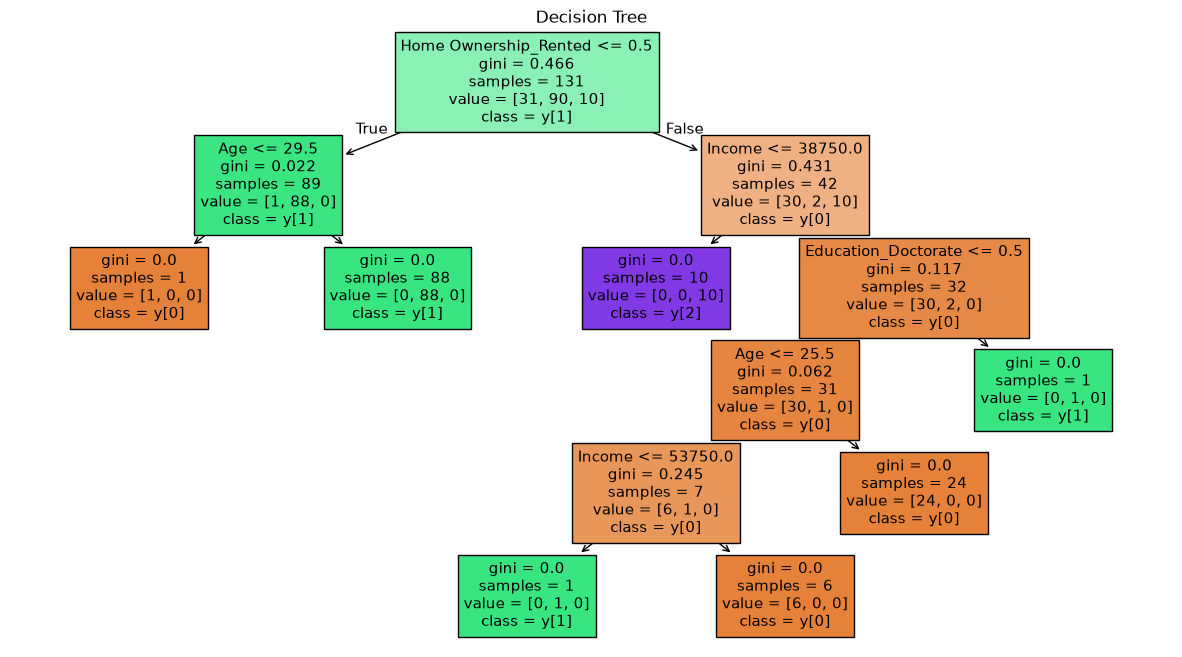

In [3]:
# ---------------------------------------------------
# 2. Separate features and target
# ---------------------------------------------------

X = df.drop("Credit Score", axis=1)
y = df["Credit Score"]
# ---------------------------------------------------
# 3. Convert categorical columns into numerical columns
# ---------------------------------------------------
X = pd.get_dummies(X, drop_first=True)

# ---------------------------------------------------
# 4. Split dataset into training and testing data
# ---------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# ---------------------------------------------------
# 5. Create Decision Tree Classifier
# ---------------------------------------------------

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

# ---------------------------------------------------
# 6. Train the model
# ---------------------------------------------------

model.fit(X_train, y_train)

# ---------------------------------------------------
# 7. Make predictions
# ---------------------------------------------------

y_pred = model.predict(X_test)

# ---------------------------------------------------
# 8. Check accuracy
# ---------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)

# ---------------------------------------------------
# 9. Classification Report
# ---------------------------------------------------

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# ---------------------------------------------------
# 10. Confusion Matrix
# ---------------------------------------------------

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
# ---------------------------------------------------
# 11. Precision and Recall Scores
# ---------------------------------------------------
print("\nPrecision Score:", precision_score(y_test, y_pred, average='weighted'))
print("Recall Score:", recall_score(y_test, y_pred, average='weighted'))


plt.figure(figsize=(15, 8))

plot_tree(
    model,
    filled=True,
    feature_names=X.columns,
    class_names=True
)

plt.title("Decision Tree")
plt.show()